In [2]:
import pandas as pd
df = pd.read_csv("city_day.csv")
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
df.shape

(29531, 16)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [5]:
df["Date"] = pd.to_datetime(df["Date"])
df.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [6]:
df_clean = df.dropna(subset=["AQI"]).copy()
df_clean.shape

(24850, 16)

In [7]:
df_clean.groupby("City")["AQI"].mean().sort_values(ascending=False)

City
Ahmedabad             452.122939
Delhi                 259.487744
Patna                 240.782042
Gurugram              225.123882
Lucknow               217.973059
Talcher               172.886819
Jorapokhar            159.251621
Brajrajnagar          150.280505
Kolkata               140.566313
Guwahati              140.111111
Jaipur                133.679159
Bhopal                132.827338
Amritsar              119.920959
Visakhapatnam         117.269855
Chennai               114.502654
Hyderabad             109.207447
Mumbai                105.352258
Kochi                 104.284810
Chandigarh             96.498328
Amaravati              95.299643
Bengaluru              94.318325
Ernakulam              92.359477
Thiruvananthapuram     75.878327
Coimbatore             73.023256
Shillong               53.795122
Aizawl                 34.765766
Name: AQI, dtype: float64

In [8]:
df_clean.groupby("City")["Date"].agg(["count", "min", "max"])

,count,min,max
City,,,
Ahmedabad,1334,2015-01-29,2020-07-01
Aizawl,111,2020-03-12,2020-07-01
Amaravati,841,2017-11-25,2020-07-01
Amritsar,1126,2017-02-28,2020-07-01
Bengaluru,1910,2015-03-21,2020-07-01
Bhopal,278,2019-09-18,2020-07-01
Brajrajnagar,713,2017-12-08,2020-06-12
Chandigarh,299,2019-09-03,2020-07-01
Chennai,1884,2015-03-24,2020-07-01


In [9]:
df_clean["Year"] = df_clean["Date"].dt.year
df_clean[df_clean["City"] == "Ahmedabad"].groupby("Year")["AQI"].agg(["count", "mean", "max"])

,count,mean,max
Year,,,
2015,263,310.950570,1247.0
2016,117,310.162393,1842.0
2017,69,558.768116,1747.0
2018,357,622.263305,2049.0
2019,352,516.352273,1719.0
2020,176,242.068182,1291.0


In [11]:
print((df_clean["AQI"] > 500).sum())
print(df_clean[df_clean["AQI"] > 500]["City"].value_counts())

543
City
Ahmedabad     412
Delhi          48
Patna          25
Gurugram       22
Lucknow        15
Jorapokhar      7
Amritsar        4
Hyderabad       4
Talcher         4
Guwahati        2
Name: count, dtype: int64


In [12]:
before = len(df_clean)
df_clean = df_clean[df_clean["AQI"] <= 500].copy()
print("Rows removed:", before - len(df_clean))
print("Rows left:", len(df_clean))
df_clean.groupby("City")["AQI"].mean().sort_values(ascending=False).head(10)

Rows removed: 543
Rows left: 24307


City
Ahmedabad       291.719089
Delhi           252.105074
Patna           235.552999
Gurugram        219.407407
Lucknow         215.193823
Talcher         170.828530
Jorapokhar      155.585079
Brajrajnagar    150.280505
Kolkata         140.566313
Guwahati        137.040568
Name: AQI, dtype: float64

In [13]:
lock_2020 = df_clean[(df_clean["Date"] >= "2020-03-25") & (df_clean["Date"] <= "2020-06-30")]
same_2019 = df_clean[(df_clean["Date"] >= "2019-03-25") & (df_clean["Date"] <= "2019-06-30")]

compare = pd.DataFrame({
    "2019": same_2019.groupby("City")["AQI"].mean(),
    "2020": lock_2020.groupby("City")["AQI"].mean()
}).dropna()

compare["Change"] = compare["2020"] - compare["2019"]
compare.sort_values("Change")

,2019,2020,Change
City,,,
Ahmedabad,374.951613,119.906250,-255.045363
Delhi,217.030612,125.520408,-91.510204
Lucknow,193.295918,107.163265,-86.132653
Gurugram,208.896907,126.204082,-82.692826
Jaipur,136.500000,95.734694,-40.765306
Patna,155.505155,118.122449,-37.382706
Visakhapatnam,106.031250,68.864583,-37.166667
Bengaluru,102.244898,65.846939,-36.397959
Amritsar,111.938776,79.500000,-32.438776


In [16]:
from scipy import stats

t, p = stats.ttest_rel(compare["2019"], compare["2020"])
print("All cities p-value:", p)

no_ahd = compare.drop("Ahmedabad")
t2, p2 = stats.ttest_rel(no_ahd["2019"], no_ahd["2020"])
print("Without Ahmedabad p-value:", p2)

print("Cities with better air:", (compare["Change"] < 0).sum(), "of", len(compare))
print("Average improvement (without Ahmedabad):", no_ahd["Change"].mean())

All cities p-value: 0.0020760627901761255
Without Ahmedabad p-value: 3.1986927500051326e-05
Cities with better air: 19 of 20
Average improvement (without Ahmedabad): -33.428094557872306


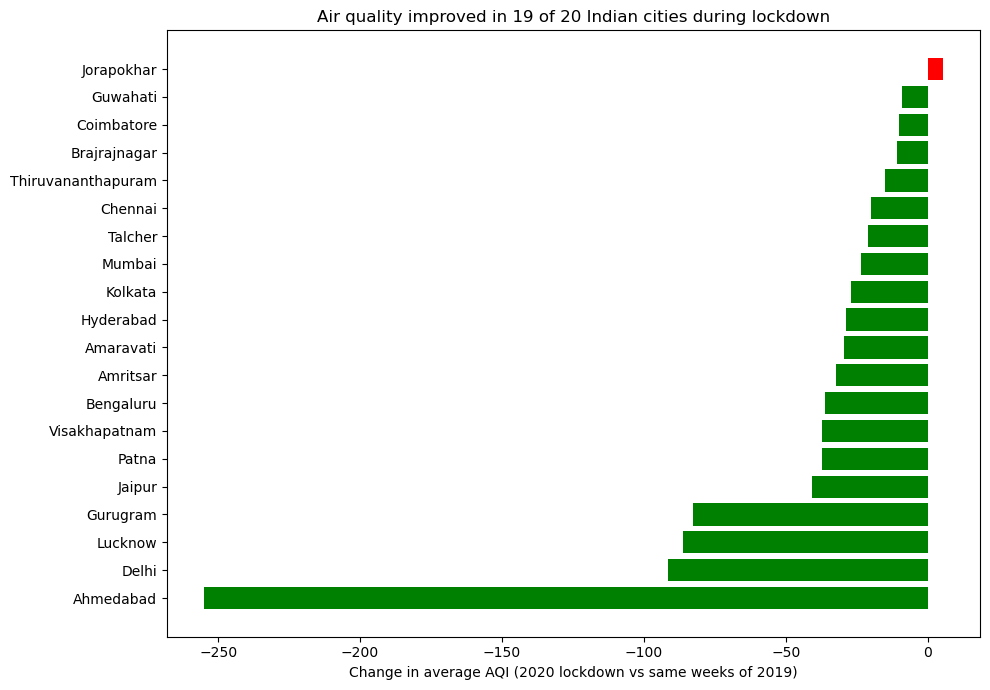

In [19]:
import matplotlib.pyplot as plt

plot_data = compare.sort_values("Change")
colors = ["green" if x < 0 else "red" for x in plot_data["Change"]]

plt.figure(figsize=(10, 7))
plt.barh(plot_data.index, plot_data["Change"], color=colors)
plt.xlabel("Change in average AQI (2020 lockdown vs same weeks of 2019)")
plt.title("Air quality improved in 19 of 20 Indian cities during lockdown")
plt.tight_layout()
plt.savefig("lockdown_aqi_change.png", dpi=150)
plt.show()